#Preparación del conjunto de datos

Este notebook realiza la **preparación del conjunto de datos (X, y)** a partir de imágenes de fondo de ojo, correspondientes a las clases "normal" y "glaucoma". Las imágenes están organizadas por categoría en carpetas y son procesadas para crear matrices de entrada y etiquetas para el entrenamiento de modelos de aprendizaje profundo.

Las principales etapas que se llevan a cabo son:

- Carga de imágenes desde las carpetas `data/train/normal` y `data/train/glaucoma`
- Visualización de muestras aleatorias de cada clase
- Redimensionamiento de imágenes a 64x64 píxeles
- Asignación de etiquetas numéricas a cada clase (0: normal, 1: glaucoma)
- División en conjuntos de entrenamiento y prueba
- Normalización de los datos de entrada
- Codificación one-hot de las etiquetas de salida
- Almacenamiento de los datos procesados en archivos `.npy` para uso posterior

>  Este procesamiento es fundamental para preparar adecuadamente los datos antes de entrenar un modelo de clasificación con redes neuronales.

# Datos de entrenamiento y validación

In [24]:
# Herramienta de Google Colab para conectar el notebook con Google Drive
from google.colab import drive
# Monta (conecta) Google Drive en este entorno para poder leer y guardar archivos ahí
drive.mount('/content/MyDrive')

Drive already mounted at /content/MyDrive; to attempt to forcibly remount, call drive.mount("/content/MyDrive", force_remount=True).


In [25]:
import os
# Cambia la carpeta de trabajo actual a la carpeta del proyecto dentro de Drive
os.chdir('/content/MyDrive/MyDrive/Proyecto_glaucoma')

In [26]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls -lth

total 240M
-rw------- 1 root root 1.5M Aug 20 10:52  Parte_0_Generación_X_y.ipynb
-rw------- 1 root root  176 Aug 17 23:00 'Evaluación modelos.gslides'
-rw------- 1 root root  90K Jun 17 19:30  Parte_1_Modelos_CNN_complejo.ipynb
-rw------- 1 root root  15K Jun 17 19:28  Parte_1_Modelos_CNN_complejo_Dataset_All.ipynb
-rw------- 1 root root 1.3M Jun 11 15:23  Parte_1_Modelos_tranferlearning_ResNet50V2_Dataset_All.ipynb
-rw------- 1 root root  94M Jun  9 23:48  modelo_ResNet50V2.keras
-rw------- 1 root root 7.2K Jun  8 19:29  Creacion_dataset_muestra.ipynb
drwx------ 5 root root 4.0K Jun  6 00:02  data_Alltrain_Allval_240test
-rw------- 1 root root 2.0M Jun  5 23:51  Parte2_prediccion_MatrizConfusion.ipynb
-rw------- 1 root root 811K May 29 07:57  Parte_1A_Modelo_CNN_AUG2.ipynb
-rw------- 1 root root 1.2M May 20 19:30  Parte_1_Modelos_CNN_complejo_Dataset_5000.ipynb
-rw------- 1 root root 1.4M May 20 19:22  modelo_CNN_complejo_muestra_5000_epocas_100.keras
-rw------- 1 root root 1.4M Ma

In [27]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls -lth data_Alltrain_Allval_240test

total 12K
drwx------ 2 root root 4.0K Jun  6 00:02 test
drwx------ 4 root root 4.0K Jun  6 00:02 train
drwx------ 4 root root 4.0K Jun  6 00:02 val


In [28]:
# 'glob' permite buscar archivos que cumplan un patrón (ej: todas las imágenes .jpg de una carpeta)
import glob

In [29]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls data_Alltrain_Allval_240test/train/normal/*.*g | wc -l

10400


In [30]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls data_Alltrain_Allval_240test/train/gl*/*.*g | wc -l

6499


In [31]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls data_Alltrain_Allval_240test/val/normal/*.*g | wc -l

480


In [32]:
# Comando de terminal: lista los archivos/carpetas para revisar qué hay disponible
!ls data_Alltrain_Allval_240test/val/gl*/*.*g | wc -l

449


In [33]:
# Obtiene la lista de rutas de todos los archivos de imagen dentro de esta carpeta
lista_normal = glob.glob('data_Alltrain_Allval_240test/train/normal/*.*g')
lista_glaucoma = glob.glob('data_Alltrain_Allval_240test/train/glaucoma/*.*g')

print(len(lista_normal), len(lista_glaucoma) )

10400 6499


In [34]:
# Librerias de ayuda
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt
# Pandas: librería para trabajar con tablas de datos
import pandas as pd
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2 as cv
from numpy import random


(512, 512, 3)
(512, 512, 3)


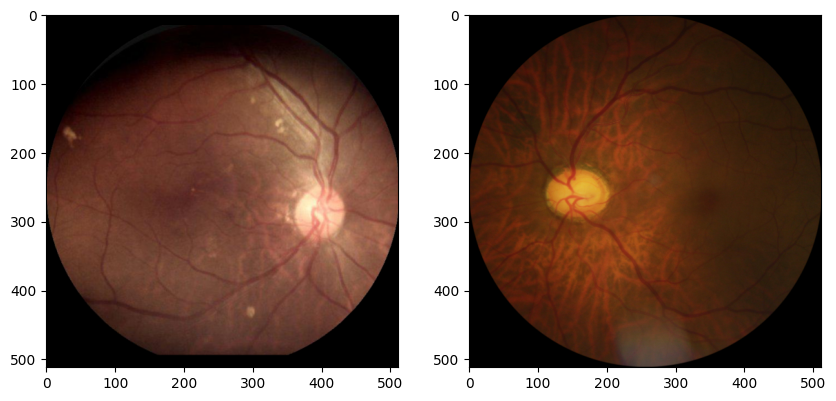

In [35]:
# Crea una nueva figura (lienzo) donde se dibujará el gráfico
plt.figure(figsize=(10,5))

# Divide la figura en una cuadrícula y selecciona en qué posición dibujar
plt.subplot(1, 2, 1)
# Lee una imagen desde el disco y la carga como un arreglo de píxeles
img = cv.imread(lista_normal[random.randint(len(lista_normal))])
# OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB) , cmap="binary")
print(img.shape)

plt.subplot(1, 2, 2)
img = cv.imread(lista_glaucoma[random.randint(len(lista_glaucoma))])
# Muestra una imagen en pantalla
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB) , cmap="binary")
print(img.shape)


# Renderiza (dibuja) el gráfico en pantalla
plt.show()

In [36]:
print(len(lista_normal), len(lista_glaucoma))

10400 6499


In [37]:
data_dict={'normal_imagenes' :   lista_normal,
           'glaucoma_imagenes'  : lista_glaucoma}

In [38]:
# Diccionario que traduce el nombre de la clase (texto) a un número (0 = normal, 1 = glaucoma) que el modelo pueda usar
labels_dict={'normal_imagenes' :   0 ,
           'glaucoma_imagenes'  : 1}

In [39]:
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np

In [40]:
#revisar
data_dict.items()

dict_items([('normal_imagenes', ['data_Alltrain_Allval_240test/train/normal/09699_n.png', 'data_Alltrain_Allval_240test/train/normal/09543_n.png', 'data_Alltrain_Allval_240test/train/normal/09780_n.png', 'data_Alltrain_Allval_240test/train/normal/09627_n.png', 'data_Alltrain_Allval_240test/train/normal/09644_n.png', 'data_Alltrain_Allval_240test/train/normal/09816_n.png', 'data_Alltrain_Allval_240test/train/normal/09567_n.png', 'data_Alltrain_Allval_240test/train/normal/09527_n.png', 'data_Alltrain_Allval_240test/train/normal/09796_n.png', 'data_Alltrain_Allval_240test/train/normal/09749_n.png', 'data_Alltrain_Allval_240test/train/normal/09674_n.png', 'data_Alltrain_Allval_240test/train/normal/09671_n.png', 'data_Alltrain_Allval_240test/train/normal/09593_n.png', 'data_Alltrain_Allval_240test/train/normal/09853_n.png', 'data_Alltrain_Allval_240test/train/normal/09709_n.png', 'data_Alltrain_Allval_240test/train/normal/09630_n.png', 'data_Alltrain_Allval_240test/train/normal/09725_n.png'

In [41]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2

# Calculate the total number of images from all categories in data_dict

##num_images = sum(len(v) for v in data_dict.values())
##X = np.zeros((num_images, 220, 220, 3), dtype=np.uint8)
##y = np.zeros((num_images,), dtype=np.int32)

##i = 0
##for label, lista_images in data_dict.items():
##    print(label)
##    for image in lista_images:
##        img = cv2.imread(image)
##       img = cv2.resize(img, (220,220))

##        X[i] = img
##        y[i] = labels_dict[label]
##        i += 1

##        if i % 200 == 0:
##            print(f"{i} imágenes procesadas")

##print( X.shape)
##print( y.shape)

##from numpy import asarray
##from numpy import save
##save('data_Alltrain_Allval_240test/train/X_train.npy', X)
##save('data_Alltrain_Allval_240test/train/y_train.npy', y)


In [42]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2
# Permite procesar varias imágenes en paralelo usando varios hilos, para acelerar el trabajo
from concurrent.futures import ThreadPoolExecutor

# ---------------------------------------------------------
# 1. Crear una lista con (ruta_imagen, etiqueta)
# ---------------------------------------------------------

datos = []

for label, lista_images in data_dict.items():

    print(label)

    for image in lista_images:
        datos.append((image, labels_dict[label]))


num_images = len(datos)

print("Total de imágenes:", num_images)


# ---------------------------------------------------------
# 2. Reservar memoria
# ---------------------------------------------------------

X = np.zeros(
    (num_images, 220, 220, 3),
    dtype=np.uint8
)

y = np.zeros(
    (num_images,),
    dtype=np.int32
)


# ---------------------------------------------------------
# 3. Función que procesa UNA imagen
# ---------------------------------------------------------

def procesar_imagen(datos_imagen):

    ruta, label = datos_imagen

    # Lee una imagen desde el disco y la carga como un arreglo de píxeles
    img = cv2.imread(ruta)

    if img is None:
        print("Error leyendo:", ruta)
        return None, label

    # Redimensiona la imagen a un tamaño fijo: todas las imágenes deben medir lo mismo para poder entrar juntas al modelo
    img = cv2.resize(
        img,
        (220, 220),
        interpolation=cv2.INTER_AREA
    )

    return img, label


# ---------------------------------------------------------
# 4. Procesamiento paralelo
# ---------------------------------------------------------

num_workers = 8

with ThreadPoolExecutor(max_workers=num_workers) as executor:

    resultados = executor.map(
        procesar_imagen,
        datos
    )

    for i, resultado in enumerate(resultados):

        img, label = resultado

        if img is not None:
            X[i] = img
            y[i] = label

        if (i + 1) % 200 == 0:
            print(
                f"{i + 1}/{num_images} imágenes procesadas"
            )


# ---------------------------------------------------------
# 5. Verificar dimensiones
# ---------------------------------------------------------

print("X:", X.shape)
print("y:", y.shape)


# ---------------------------------------------------------
# 6. Guardar
# ---------------------------------------------------------

# Guarda un arreglo NumPy en disco para poder reutilizarlo después sin recalcularlo
np.save(
    'data_Alltrain_Allval_240test/train/X_train.npy',
    X
)

# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
np.save(
    'data_Alltrain_Allval_240test/train/y_train.npy',
    y
)

print("Archivos guardados correctamente.")

normal_imagenes
glaucoma_imagenes
Total de imágenes: 16899
200/16899 imágenes procesadas
400/16899 imágenes procesadas
600/16899 imágenes procesadas
800/16899 imágenes procesadas
1000/16899 imágenes procesadas
1200/16899 imágenes procesadas
1400/16899 imágenes procesadas
1600/16899 imágenes procesadas
1800/16899 imágenes procesadas
2000/16899 imágenes procesadas
2200/16899 imágenes procesadas
2400/16899 imágenes procesadas
2600/16899 imágenes procesadas
2800/16899 imágenes procesadas
3000/16899 imágenes procesadas
3200/16899 imágenes procesadas
3400/16899 imágenes procesadas
3600/16899 imágenes procesadas
3800/16899 imágenes procesadas
4000/16899 imágenes procesadas
4200/16899 imágenes procesadas
4400/16899 imágenes procesadas
4600/16899 imágenes procesadas
4800/16899 imágenes procesadas
5000/16899 imágenes procesadas
5200/16899 imágenes procesadas
5400/16899 imágenes procesadas
5600/16899 imágenes procesadas
5800/16899 imágenes procesadas
6000/16899 imágenes procesadas
6200/16899 imág

# Datos de test

In [43]:
#lista_normal_test = glob.glob('data_Alltrain_Allval_240test/test/normal/*.*g')
#lista_glaucoma_test = glob.glob('data_Alltrain_Allval_240test/test/glaucoma/*.*g')



In [44]:
#print(len(lista_normal_test), len(lista_glaucoma_test))

In [45]:
#data_dict_test={'normal_imagenes' :   lista_normal_test,
#           'glaucoma_imagenes'  : lista_glaucoma_test}

In [46]:
#data_dict_test.items()

In [47]:
'''
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2

# Calculate the total number of images from all categories in data_dict
num_images = sum(len(v) for v in data_dict_test.values())
# Reserva de antemano un arreglo de ceros del tamaño exacto que se va a necesitar (más rápido que ir agregando imágenes una por una)
X = np.zeros((num_images, 220, 220, 3), dtype=np.uint8)
y = np.zeros((num_images,), dtype=np.int32)

i = 0
for label, lista_images in data_dict_test.items():
    print(label)
    for image in lista_images:
        # Lee una imagen desde el disco y la carga como un arreglo de píxeles
        img = cv2.imread(image)
        # Redimensiona la imagen a un tamaño fijo: todas las imágenes deben medir lo mismo para poder entrar juntas al modelo
        img = cv2.resize(img, (220,220))

        X[i] = img
        y[i] = labels_dict[label]
        i += 1
        if i % 50 == 0:
            print(f"{i} imágenes procesadas")


import numpy as np

print( X.shape)
print( y.shape)

save('data_Alltrain_Allval_240test/test/X_test.npy', X)
save('data_Alltrain_Allval_240test/test/y_test.npy', y)

'''


'\nimport numpy as np\nimport cv2\n\n# Calculate the total number of images from all categories in data_dict\nnum_images = sum(len(v) for v in data_dict_test.values())\nX = np.zeros((num_images, 220, 220, 3), dtype=np.uint8)\ny = np.zeros((num_images,), dtype=np.int32)\n\ni = 0\nfor label, lista_images in data_dict_test.items():\n    print(label)\n    for image in lista_images:\n        img = cv2.imread(image)\n        img = cv2.resize(img, (220,220))\n\n        X[i] = img\n        y[i] = labels_dict[label]\n        i += 1\n        if i % 50 == 0:\n            print(f"{i} imágenes procesadas")\n\n\nimport numpy as np\n\nprint( X.shape)\nprint( y.shape)\n\nsave(\'data_Alltrain_Allval_240test/test/X_test.npy\', X)\nsave(\'data_Alltrain_Allval_240test/test/y_test.npy\', y)\n\n'

# Datos val

In [48]:
# Obtiene la lista de rutas de todos los archivos de imagen dentro de esta carpeta
lista_normal_val = glob.glob('data_Alltrain_Allval_240test/val/normal/*.*g')
lista_glaucoma_val = glob.glob('data_Alltrain_Allval_240test/val/glaucoma/*.*g')

In [49]:
print(len(lista_normal_val), len(lista_glaucoma_val))

480 449


In [50]:
data_dict_val={'normal_imagenes' :   lista_normal_val,
           'glaucoma_imagenes'  : lista_glaucoma_val}

In [51]:
data_dict_val.items()

dict_items([('normal_imagenes', ['data_Alltrain_Allval_240test/val/normal/00236_n.png', 'data_Alltrain_Allval_240test/val/normal/00202_n.png', 'data_Alltrain_Allval_240test/val/normal/00129_n.png', 'data_Alltrain_Allval_240test/val/normal/00096_n.png', 'data_Alltrain_Allval_240test/val/normal/00079_n.png', 'data_Alltrain_Allval_240test/val/normal/00625_n.png', 'data_Alltrain_Allval_240test/val/normal/00549_n.png', 'data_Alltrain_Allval_240test/val/normal/00587_n.png', 'data_Alltrain_Allval_240test/val/normal/00597_n.png', 'data_Alltrain_Allval_240test/val/normal/00374_n.png', 'data_Alltrain_Allval_240test/val/normal/00314_n.png', 'data_Alltrain_Allval_240test/val/normal/00723_n.png', 'data_Alltrain_Allval_240test/val/normal/00675_n.png', 'data_Alltrain_Allval_240test/val/normal/00571_n.png', 'data_Alltrain_Allval_240test/val/normal/00377_n.png', 'data_Alltrain_Allval_240test/val/normal/00323_n.png', 'data_Alltrain_Allval_240test/val/normal/00358_n.png', 'data_Alltrain_Allval_240test/va

In [52]:
##import numpy as np
##import cv2

##num_images = sum(len(v) for v in data_dict_val.values())
##X = np.zeros((num_images, 220, 220, 3), dtype=np.uint8)
##y = np.zeros((num_images,), dtype=np.int32)

##i = 0
##for label, lista_images in data_dict_val.items():
##    print(label)
##    for image in lista_images:
##        img = cv2.imread(image)
##        img = cv2.resize(img, (220, 220))

##        X[i] = img
##        y[i] = labels_dict[label]
##        i += 1
##        if i % 50 == 0:
##            print(f"{i} imágenes procesadas")

##print( X.shape)
##print( y.shape)
##from numpy import asarray
##from numpy import save
##save('data_Alltrain_Allval_240test/val/X_val.npy', X)
##save('data_Alltrain_Allval_240test/val/y_val.npy', y)

In [53]:
# NumPy: librería para trabajar con arreglos numéricos (matrices) de forma eficiente
import numpy as np
# OpenCV: librería para leer, procesar y transformar imágenes
import cv2
# Permite procesar varias imágenes en paralelo usando varios hilos, para acelerar el trabajo
from concurrent.futures import ThreadPoolExecutor
import time

# Evita que cada worker cree hilos internos adicionales de OpenCV
# Limita los hilos internos de OpenCV para que no compita con los hilos del ThreadPoolExecutor
cv2.setNumThreads(1)

# ---------------------------------------------------------
# 1. Crear lista con (ruta_imagen, etiqueta)
# ---------------------------------------------------------

datos = []

for label, lista_images in data_dict_val.items():

    print(label)

    for image in lista_images:
        datos.append((image, labels_dict[label]))


num_images = len(datos)

print("Total de imágenes de validación:", num_images)


# ---------------------------------------------------------
# 2. Reservar memoria
# ---------------------------------------------------------

X = np.zeros(
    (num_images, 220, 220, 3),
    dtype=np.uint8
)

y = np.zeros(
    (num_images,),
    dtype=np.int32
)


# ---------------------------------------------------------
# 3. Función para procesar una imagen
# ---------------------------------------------------------

def procesar_imagen(datos_imagen):

    ruta, label = datos_imagen

    # Lee una imagen desde el disco y la carga como un arreglo de píxeles
    img = cv2.imread(ruta)

    # Verificar que la imagen se haya leído correctamente
    if img is None:
        print("Error leyendo:", ruta)
        return None, label

    # Redimensiona la imagen a un tamaño fijo: todas las imágenes deben medir lo mismo para poder entrar juntas al modelo
    img = cv2.resize(
        img,
        (220, 220),
        interpolation=cv2.INTER_AREA
    )

    return img, label


# ---------------------------------------------------------
# 4. Procesamiento paralelo
# ---------------------------------------------------------

num_workers = 8

inicio = time.time()

with ThreadPoolExecutor(max_workers=num_workers) as executor:

    resultados = executor.map(
        procesar_imagen,
        datos
    )

    for i, resultado in enumerate(resultados):

        img, label = resultado

        if img is not None:
            X[i] = img
            y[i] = label

        if (i + 1) % 50 == 0:
            print(
                f"{i + 1}/{num_images} imágenes procesadas"
            )


fin = time.time()


# ---------------------------------------------------------
# 5. Mostrar resultados
# ---------------------------------------------------------

print("\nProcesamiento terminado")

print("X:", X.shape)
print("y:", y.shape)

print(
    f"Tiempo total: {fin - inicio:.2f} segundos"
)

print(
    f"Tiempo total: {(fin - inicio)/60:.2f} minutos"
)


# ---------------------------------------------------------
# 6. Guardar archivos
# ---------------------------------------------------------

# Guarda un arreglo NumPy en disco para poder reutilizarlo después sin recalcularlo
np.save(
    'data_Alltrain_Allval_240test/val/X_val.npy',
    X
)

# Guarda el modelo entrenado (su arquitectura y pesos aprendidos) en un archivo .keras para reutilizarlo sin re-entrenar
np.save(
    'data_Alltrain_Allval_240test/val/y_val.npy',
    y
)

print("\nArchivos guardados correctamente.")

normal_imagenes
glaucoma_imagenes
Total de imágenes de validación: 929
50/929 imágenes procesadas
100/929 imágenes procesadas
150/929 imágenes procesadas
200/929 imágenes procesadas
250/929 imágenes procesadas
300/929 imágenes procesadas
350/929 imágenes procesadas
400/929 imágenes procesadas
450/929 imágenes procesadas
500/929 imágenes procesadas
550/929 imágenes procesadas
600/929 imágenes procesadas
650/929 imágenes procesadas
700/929 imágenes procesadas
750/929 imágenes procesadas
800/929 imágenes procesadas
850/929 imágenes procesadas
900/929 imágenes procesadas

Procesamiento terminado
X: (929, 220, 220, 3)
y: (929,)
Tiempo total: 114.82 segundos
Tiempo total: 1.91 minutos

Archivos guardados correctamente.


In [54]:
print(X.shape)
print(y.shape)
# Cuenta cuántos elementos únicos hay (aquí, cuántas imágenes hay de cada clase)
print(np.unique(y, return_counts=True))
print(X[0].min(), X[0].max())
print(X[1].min(), X[1].max())

(929, 220, 220, 3)
(929,)
(array([0, 1], dtype=int32), array([480, 449]))
0 255
0 255


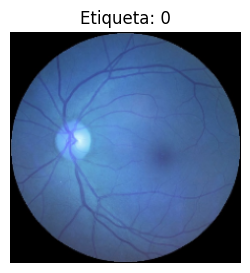

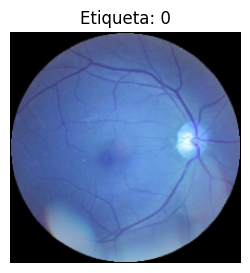

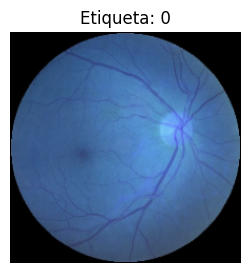

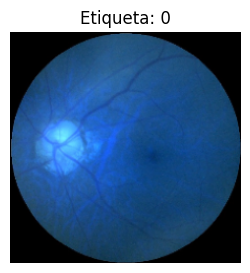

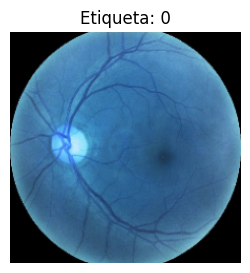

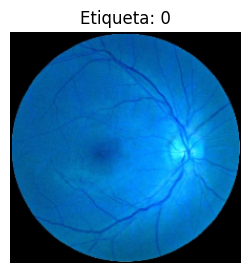

In [55]:
# Matplotlib: librería para crear gráficos y mostrar imágenes
import matplotlib.pyplot as plt

for k in range(6):
    # Crea una nueva figura (lienzo) donde se dibujará el gráfico
    plt.figure(figsize=(3,3))
    # OpenCV lee las imágenes en formato de color BGR; esto las convierte a RGB, que es el formato correcto para mostrarlas con matplotlib
    plt.imshow(cv2.cvtColor(X[k], cv2.COLOR_BGR2RGB))
    # Agrega un título al gráfico o imagen mostrada
    plt.title(f"Etiqueta: {y[k]}")
    # Oculta o ajusta los ejes del gráfico (por estética)
    plt.axis('off')
    # Renderiza (dibuja) el gráfico en pantalla
    plt.show()